# Human Beer Game: measurement and sample-size planning

**No human data. No API calls or participant launches.** Run from top to bottom with **Beer Game (.venv)**. Change the assumptions in cell 2, then rerun the following cells. These calculations do not predict whether the hypotheses are true.

Start with `../README.md`; equations are in `../02_MEASUREMENT_MODEL.md` and `../03_SAMPLE_SIZE.md`. The main design has **four time × education cells**. H5 uses a **separate individual cohort** after routine acquisition.


In [1]:
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts/plan_human_study.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the beergame repository.')
spec = importlib.util.spec_from_file_location('human_planning', ROOT / 'scripts/plan_human_study.py')
planning = importlib.util.module_from_spec(spec)
spec.loader.exec_module(planning)
print('Offline planning only. Repository:', ROOT)


Offline planning only. Repository: D:\beergame


## 1. Edit these assumptions

`gap_sd` is the SD of **estimated participant response gaps**, including measurement error. `cost_sd` is the SD of **whole-chain costs**, not individual-role costs. Interaction effects have their own magnitudes. Every value below is illustrative, not estimated from AI or humans.


In [2]:
family_size = 8
family_alpha = 0.05
target_power = 0.80
people_per_chain = 4
icc = 0.10

gap_sd = 0.25
gap_simple_difference = 0.125
gap_interaction_difference = 0.125

cost_sd = 1000.0
cost_simple_difference = 500.0
cost_interaction_difference = 500.0

h5_persistence_sd = 0.40
h5_persistence_difference = 0.20
h5_adoption_fraction = 0.80
h5_retention = 0.90

assert family_size >= 1 and 0 < family_alpha < 1
assert 0 < target_power < 1 and 0 <= icc < 1
assert all(v > 0 for v in [gap_sd, cost_sd, h5_persistence_sd])
assert 0 < h5_adoption_fraction <= 1 and 0 < h5_retention <= 1
alpha = family_alpha / family_size
design_effect = 1 + (people_per_chain - 1) * icc
gap_chain_variance = gap_sd**2 * design_effect / people_per_chain
print(f'Planning alpha per endpoint: {alpha:g}; design effect: {design_effect:g}')


Planning alpha per endpoint: 0.00625; design effect: 1.3


## 2. Main-game recruitment scenarios

One block contains one chain in each of the four cells. Thus k chains/cell means **4k chains and 16k people**. Power uses a t-test on k block contrasts, with k−1 degrees of freedom. No covariance benefit from matching demand is assumed.

$$V_L=2v\quad\text{(simple)},\qquad V_L=4v\quad\text{(interaction)}.$$

The largest requirement below only covers the displayed endpoints. The final enrollment target must also consider H4a/H4b and missing data. It is not a recruitment recommendation without human pilot estimates.


In [3]:
scenarios = [
    ('G: H1/H3 simple', gap_simple_difference, 2*gap_chain_variance),
    ('G: H6a interaction', gap_interaction_difference, 4*gap_chain_variance),
    ('Cost: H2 simple', cost_simple_difference, 2*cost_sd**2),
    ('Cost: H6b interaction', cost_interaction_difference, 4*cost_sd**2),
]
rows = []
for name, difference, variance in scenarios:
    k = planning.required_size(lambda n: planning.contrast_power(n, difference, variance, alpha), target_power)
    rows.append({'endpoint': name, 'chains_per_cell': k, 'total_chains': 4*k,
                 'total_people': 4*people_per_chain*k,
                 'achieved_power': planning.contrast_power(k, difference, variance, alpha),
                 'power_at_10_chains_per_cell': planning.contrast_power(10, difference, variance, alpha)})
display(pd.DataFrame(rows))


,endpoint,chains_per_cell,total_chains,total_people,achieved_power,power_at_10_chains_per_cell
0,G: H1/H3 simple,38,152,608,0.814306,0.124595
1,G: H6a interaction,71,284,1136,0.805555,0.053779
2,Cost: H2 simple,107,428,1712,0.804590,0.034097
3,Cost: H6b interaction,209,836,3344,0.801589,0.018676


## 3. Prospective power versus chain count

This plots **power under the assumptions above**, not observed p-values and not the sample size at which significance is guaranteed. The dashed horizontal line is the target power. After collection, a sample-size trajectory of results would be a different, descriptive plot.


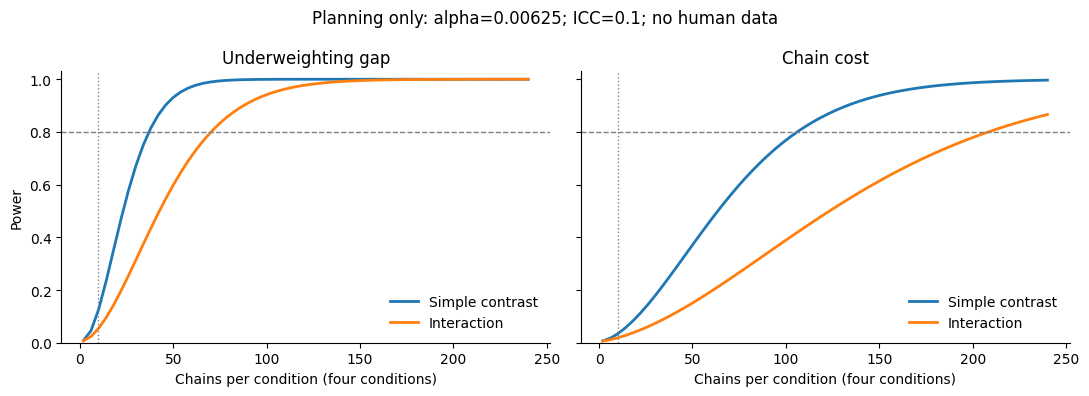

In [4]:
ks = np.unique(np.linspace(2, 240, 60).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, subset, title in [(axes[0], scenarios[:2], 'Underweighting gap'),
                           (axes[1], scenarios[2:], 'Chain cost')]:
    for name, difference, variance in subset:
        powers = [planning.contrast_power(int(k), difference, variance, alpha) for k in ks]
        ax.plot(ks, powers, label='Interaction' if 'interaction' in name else 'Simple contrast', lw=2)
    ax.axhline(target_power, color='gray', ls='--', lw=1)
    ax.axvline(10, color='gray', ls=':', lw=1)
    ax.set(title=title, xlabel='Chains per condition (four conditions)', ylim=(0,1.03))
    ax.legend(frameon=False)
    ax.spines[['top','right']].set_visible(False)
axes[0].set_ylabel('Power')
fig.suptitle(f'Planning only: alpha={alpha:g}; ICC={icc:g}; no human data')
fig.tight_layout()
plt.show()


## 4. H5: separate routine-transfer participants

Only eligible routine adopters are randomized, **after** the common-time acquisition phase. n below is people per time arm, not chains. The primary endpoint is each person's mean persistence on the first eight transfer trials. Adoption and retention assumptions inflate invitations; the main-game people are not automatically reused.


In [5]:
d_h5 = h5_persistence_difference / h5_persistence_sd
n_h5 = planning.required_size(lambda n: planning.h5_power(n, d_h5, alpha), target_power)
invitations = int(np.ceil(2*n_h5/(h5_adoption_fraction*h5_retention)))
display(pd.DataFrame([{'people_per_time_arm': n_h5, 'total_randomized_adopters': 2*n_h5,
                       'expected_invitations': invitations,
                       'achieved_power': planning.h5_power(n_h5, d_h5, alpha)}]))


,people_per_time_arm,total_randomized_adopters,expected_invitations,achieved_power
0,105,210,292,0.803965


## 5. Verify what the gap measures

The following orders are **synthetic arithmetic examples**, not simulated student evidence or human data.

$$G=\kappa_I-\kappa_P=b_P-b_I,\qquad w=\kappa_P/\kappa_I.$$

Equal partial adjustment gives G=0 even though both responses are too small relative to this task's benchmark. A ratio near an uncertain zero inventory slope must not be interpreted.


In [6]:
examples = []
for name, response in [
    ('Full response to both', lambda x: x.demand-x.inventory-x.pipeline),
    ('Ignores pipeline', lambda x: x.demand-x.inventory),
    ('Half response to both', lambda x: (x.demand-x.inventory-x.pipeline)/2),
    ('Worked example', lambda x: 22-.75*x.inventory-.25*x.pipeline),
]:
    task = planning.stock_states()
    task['order'] = response(task)
    estimate = planning.estimate_stock_weights(task)
    examples.append({'synthetic_example': name, 'inventory_response': estimate['k_inventory'],
                     'pipeline_response': estimate['k_pipeline'], 'gap': estimate['gap'],
                     'relative_weight': estimate['relative_pipeline_weight_descriptive']})
display(pd.DataFrame(examples).round(4))

# In a future analysis, pass one actual person's validated 32 rows, never fill missing cells:
# actual = pd.read_csv(path_to_human_stock_task)
# estimate = planning.estimate_stock_weights(actual[actual.participant_id == participant_id])


,synthetic_example,inventory_response,pipeline_response,gap,relative_weight
0,Full response to both,1.00,1.00,0.0,1.0000
1,Ignores pipeline,1.00,-0.00,1.0,-0.0000
2,Half response to both,0.50,0.50,0.0,1.0000
3,Worked example,0.75,0.25,0.5,0.3333


## 6. Verify the H5 change in benchmark

Before the change, all pipeline stock arrives in time. After the change, only the early shipment does.

$$q^{old}=48-I-P_E-P_L,\quad q^{new}=48-I-P_E,\quad R=(q^{new}-q)/P_L.$$

R=1 repeats the old rule; R=0 fully adapts. Correctly ignoring the too-late shipment is **not** underweighting an economically usable pipeline. This distinction is essential for H5.


In [7]:
state = planning.routine_states().query("phase == 'transfer' and block == 1").iloc[0]
example_rows = []
for label, order in [('Old rule', state.old_benchmark), ('Adapted rule', state.new_benchmark)]:
    r = planning.routine_persistence(order, state.inventory, state.early_pipeline, state.late_pipeline)
    example_rows.append({'synthetic_choice': label, 'order': order, 'persistence': r})
display(pd.DataFrame(example_rows))
print('Finished offline calculations. Zero human records collected.')


,synthetic_choice,order,persistence
0,Old rule,32,1.0
1,Adapted rule,40,0.0


Finished offline calculations. Zero human records collected.
